In [1]:
from typing import Literal
from langgraph.types import Command
from langgraph.graph import StateGraph, MessagesState, START, END
from langchain_core.messages import AIMessage

def agent_1(state: MessagesState) -> Command[Literal["agent_2"]]:
    messages = AIMessage(content="1번 에이전트 메시지입니다.")
    return Command(
        goto="agent_2",
        update={"messages":[messages]},
    )

def agent_2(state: MessagesState) -> Command[Literal[END]]:
    message = AIMessage(content="2번 에이전트 메시지입니다.")
    return Command(
        goto=END,
        update={"messages": [message]},
    )
    
graph_builder = StateGraph(MessagesState)
graph_builder.add_node("agent_1", agent_1)
graph_builder.add_node("agent_2", agent_2)

graph_builder.add_edge(START, "agent_1")

graph = graph_builder.compile()

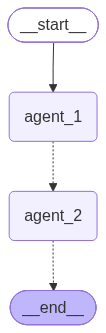

In [2]:
graph

In [3]:
for chunk in graph.stream({"messages":[]}, stream_mode="values"):
    print(chunk)

{'messages': []}
{'messages': [AIMessage(content='1번 에이전트 메시지입니다.', additional_kwargs={}, response_metadata={}, id='e35b4a23-ec2c-4614-afdc-52101cccd35c', tool_calls=[], invalid_tool_calls=[])]}
{'messages': [AIMessage(content='1번 에이전트 메시지입니다.', additional_kwargs={}, response_metadata={}, id='e35b4a23-ec2c-4614-afdc-52101cccd35c', tool_calls=[], invalid_tool_calls=[]), AIMessage(content='2번 에이전트 메시지입니다.', additional_kwargs={}, response_metadata={}, id='773ad303-12bc-4cb0-b4b1-db0be9d97456', tool_calls=[], invalid_tool_calls=[])]}


In [8]:
from typing import Literal
from langgraph.types import Command
from langgraph.graph import StateGraph, MessagesState, START, END
from langchain_core.messages import AIMessage

class State(MessagesState):
    foo: str

def agent_1(state: State) -> Command[Literal["agent_2", "agent_3"]]:
    messages = AIMessage(content="1번 에이전트 메시지 입니다.")
    if state["foo"] == "bar":
        return Command(
            goto="agent_3",
            update={"messages": [ messages], "foo": "baz"}
        )
    return Command(
        goto="agent_2",
        update={"messages":[messages]},
    )

def agent_2(staet: State):
    message = AIMessage(content="2번 에이전트 메시지 입니다.")
    return Command(
        goto=END,
        update={"messages": [message]},
    )

def agent_3(state: State):
    message = AIMessage(content="3번 에이전트 메시지 입니다.")
    return Command(
        goto=END,
        update={"messages":[message]},
    )

graph_builder = StateGraph(State)
graph_builder.add_node("agent_1", agent_1)
graph_builder.add_node("agent_2", agent_2)
graph_builder.add_node("agent_3", agent_3)

graph_builder.add_edge(START, "agent_1")

graph = graph_builder.compile()


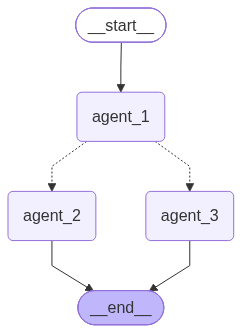

In [5]:
graph

In [9]:
for chunk in graph.stream({"messages": [], "foo": "bar"}, stream_mode="values"):
    print(chunk)

{'messages': [], 'foo': 'bar'}
{'messages': [AIMessage(content='1번 에이전트 메시지 입니다.', additional_kwargs={}, response_metadata={}, id='b73362b7-4871-4773-a874-4000a39123e1', tool_calls=[], invalid_tool_calls=[])], 'foo': 'baz'}
{'messages': [AIMessage(content='1번 에이전트 메시지 입니다.', additional_kwargs={}, response_metadata={}, id='b73362b7-4871-4773-a874-4000a39123e1', tool_calls=[], invalid_tool_calls=[]), AIMessage(content='3번 에이전트 메시지 입니다.', additional_kwargs={}, response_metadata={}, id='54c29354-2aee-4825-ab12-5e0ef369ceb0', tool_calls=[], invalid_tool_calls=[])], 'foo': 'baz'}


In [10]:
for chunk in graph.stream({"messages" : [], "foo": "baz"}, stream_mode="values"):
    print(chunk)
    

{'messages': [], 'foo': 'baz'}
{'messages': [AIMessage(content='1번 에이전트 메시지 입니다.', additional_kwargs={}, response_metadata={}, id='06181d3b-e115-4563-8b21-27c5f1a89289', tool_calls=[], invalid_tool_calls=[])], 'foo': 'baz'}
{'messages': [AIMessage(content='1번 에이전트 메시지 입니다.', additional_kwargs={}, response_metadata={}, id='06181d3b-e115-4563-8b21-27c5f1a89289', tool_calls=[], invalid_tool_calls=[]), AIMessage(content='2번 에이전트 메시지 입니다.', additional_kwargs={}, response_metadata={}, id='7b4c1f77-13dc-404b-8a3d-ee140c2c961f', tool_calls=[], invalid_tool_calls=[])], 'foo': 'baz'}
